# U.S. Recession Forecasting — Exploratory Data Analysis

This notebook explores the macroeconomic dataset used for recession
forecasting. The analysis focuses on the distribution of recession periods,
relationships between economic indicators, and how selected indicators
behave around historical U.S. recessions.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)


In [2]:
df = pd.read_csv(
    "../data/processed/macroeconomic_monthly.csv",
    index_col=0,
    parse_dates=True
)

df.head()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
1986-01-01,6.7,366750.0,109.9,8.14,1.051429,1.891905,55.7481,1972.0,95.6,2.241429,0.0
1986-02-01,7.2,369500.0,109.7,7.86,0.736842,1.413684,55.3568,1848.0,95.9,2.408421,0.0
1986-03-01,7.2,381200.0,109.1,7.48,0.564000,1.014500,54.9625,1876.0,95.1,2.716500,0.0
1986-04-01,7.1,385750.0,108.7,6.99,0.604091,1.063636,55.0413,1933.0,96.2,2.891364,0.0
1986-05-01,7.2,386000.0,109.0,6.85,0.642381,1.374762,55.1226,1854.0,94.8,2.576190,0.0


## 1. Dataset Overview

Before exploring individual economic indicators, I first inspect the
structure of the cleaned dataset.

In [3]:
df.shape

(487, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 487 entries, 1986-01-01 to 2026-08-01
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   unemployment_rate      487 non-null    float64
 1   initial_claims         487 non-null    float64
 2   cpi                    487 non-null    float64
 3   fed_funds_rate         487 non-null    float64
 4   yield_spread_10y_2y    487 non-null    float64
 5   yield_spread_10y_3m    487 non-null    float64
 6   industrial_production  487 non-null    float64
 7   housing_starts         487 non-null    float64
 8   consumer_sentiment     487 non-null    float64
 9   credit_spread          487 non-null    float64
 10  recession              487 non-null    float64
dtypes: float64(11)
memory usage: 45.7 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
unemployment_rate,487.0,5.683778,1.666186,3.400000,4.400000,5.400000,6.600000,1.480000e+01
initial_claims,487.0,361964.887064,261168.208413,197500.000000,284450.000000,333500.000000,383000.000000,4.663250e+06
cpi,487.0,202.760257,58.371181,108.700000,155.250000,200.700000,239.829000,3.341310e+02
fed_funds_rate,487.0,3.350719,2.637173,0.050000,0.475000,3.300000,5.330000,9.850000e+00
yield_spread_10y_2y,487.0,0.963019,0.883210,-0.929000,0.245276,0.824091,1.675682,2.834211e+00
yield_spread_10y_3m,487.0,1.454228,1.246244,-1.734545,0.508295,1.483182,2.510143,3.684545e+00
industrial_production,487.0,87.431464,15.410612,54.900500,73.630100,92.949900,100.160450,1.041004e+02
housing_starts,487.0,1351.184805,368.221282,478.000000,1146.000000,1382.000000,1588.500000,2.273000e+03
consumer_sentiment,487.0,84.824641,14.001132,44.800000,74.450000,88.900000,94.700000,1.120000e+02
credit_spread,487.0,2.268156,0.689178,1.289524,1.744043,2.131739,2.672859,6.013636e+00


## 2. Recession Distribution

The target variable indicates whether the U.S. economy was in recession
during each month. Since recessions occur less frequently than expansions,
I first examine the class distribution before building any prediction models.

In [6]:
recession_counts = df["recession"].value_counts().sort_index()

recession_counts

recession
0.0    451
1.0     36
Name: count, dtype: int64

In [7]:
recession_percentages = (
    df["recession"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

recession_percentages

recession
0.0    92.607803
1.0     7.392197
Name: proportion, dtype: float64

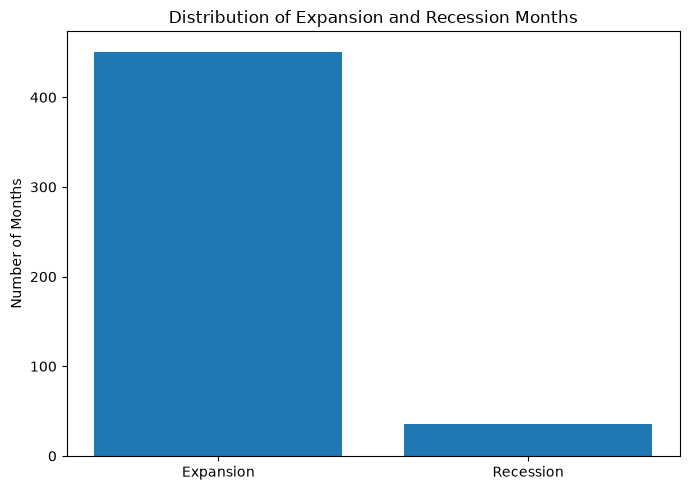

In [8]:
labels = ["Expansion", "Recession"]

plt.figure(figsize=(7, 5))

plt.bar(
    labels,
    recession_counts.values
)

plt.title("Distribution of Expansion and Recession Months")
plt.ylabel("Number of Months")

plt.tight_layout()
plt.show()

The dataset contains substantially more expansion months than recession
months. This class imbalance is important for the modeling stage because
accuracy alone may give a misleading impression of model performance.

A model that predicts expansion for every observation could achieve a
relatively high accuracy while failing to identify recessions.

In [9]:
recession_months = df[df["recession"] == 1]

recession_months.index

DatetimeIndex(['1990-08-01', '1990-09-01', '1990-10-01', '1990-11-01',
               '1990-12-01', '1991-01-01', '1991-02-01', '1991-03-01',
               '2001-04-01', '2001-05-01', '2001-06-01', '2001-07-01',
               '2001-08-01', '2001-09-01', '2001-10-01', '2001-11-01',
               '2008-01-01', '2008-02-01', '2008-03-01', '2008-04-01',
               '2008-05-01', '2008-06-01', '2008-07-01', '2008-08-01',
               '2008-09-01', '2008-10-01', '2008-11-01', '2008-12-01',
               '2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2020-03-01', '2020-04-01'],
              dtype='datetime64[us]', freq=None)

In [10]:
recession_start = (
    (df["recession"] == 1) &
    (df["recession"].shift(1, fill_value=0) == 0)
)

recession_end = (
    (df["recession"] == 1) &
    (df["recession"].shift(-1, fill_value=0) == 0)
)

starts = df.index[recession_start]
ends = df.index[recession_end]

recession_periods = pd.DataFrame({
    "Start": starts,
    "End": ends
})

recession_periods

,Start,End
0,1990-08-01,1991-03-01
1,2001-04-01,2001-11-01
2,2008-01-01,2009-06-01
3,2020-03-01,2020-04-01


Expansion months make up approximately 92.6% of the dataset, while only
7.4% of the observations are recession months. This shows that the target
variable is strongly imbalanced.

Because of this imbalance, accuracy alone will not be sufficient for
evaluating the prediction models. A model could achieve high accuracy by
mostly predicting expansions while still failing to identify recessions.

## 3. Historical Recession Periods

The recession indicator is visualized over time to identify the recession
periods represented in the dataset.

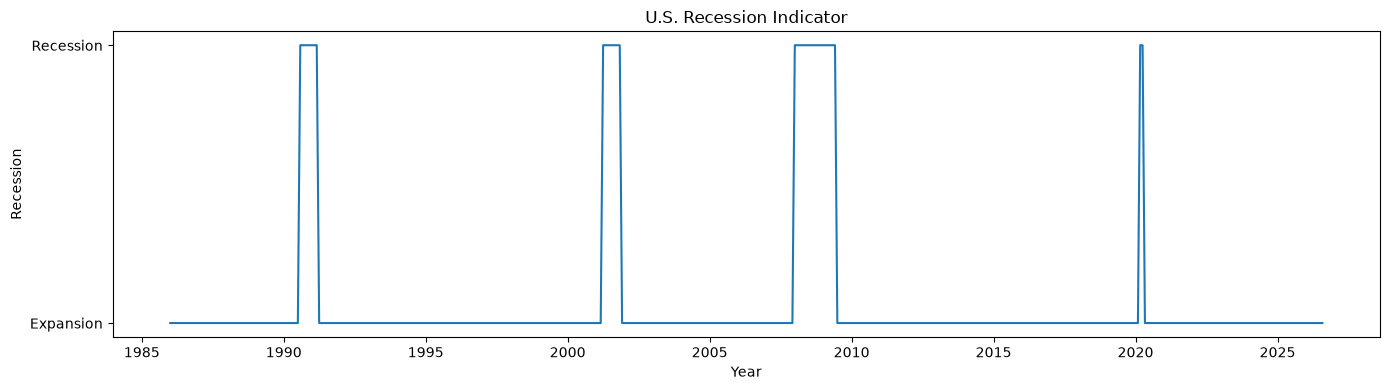

In [11]:
plt.figure(figsize=(14, 4))

plt.plot(
    df.index,
    df["recession"]
)

plt.title("U.S. Recession Indicator")
plt.xlabel("Year")
plt.ylabel("Recession")
plt.yticks([0, 1], ["Expansion", "Recession"])

plt.tight_layout()
plt.show()

## 4. Unemployment and Recessions

The unemployment rate is one of the main indicators of labor market
conditions. I compare its historical development with recession periods
to examine how unemployment behaves around economic downturns.

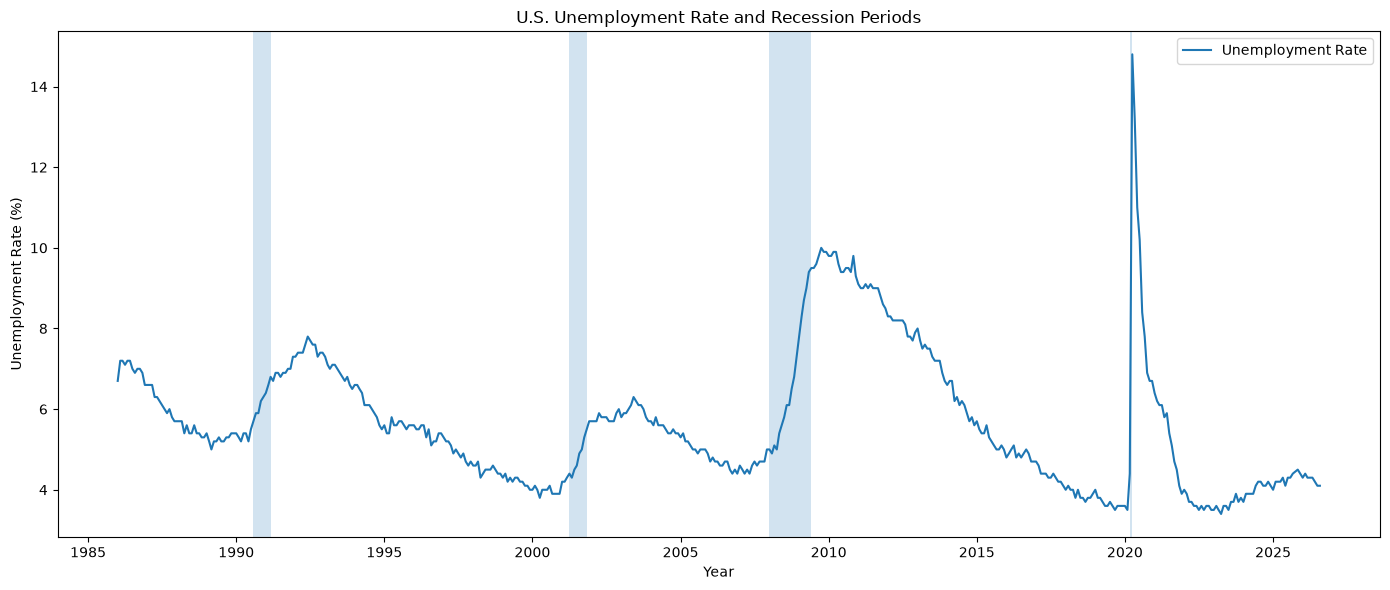

In [12]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df.index,
    df["unemployment_rate"],
    label="Unemployment Rate"
)

for _, period in recession_periods.iterrows():
    ax.axvspan(
        period["Start"],
        period["End"],
        alpha=0.2
    )

ax.set_title("U.S. Unemployment Rate and Recession Periods")
ax.set_xlabel("Year")
ax.set_ylabel("Unemployment Rate (%)")
ax.legend()

plt.tight_layout()
plt.show()

The unemployment rate tends to increase around recession periods, although
the increase is not necessarily observed before the recession begins.
This suggests that unemployment may be useful for identifying deteriorating
economic conditions, but further analysis is needed to determine its value
for forecasting recessions in advance.

## 5. Yield Curve and Recessions

The yield spread represents the difference between long-term and short-term
interest rates. I examine whether changes in the yield curve occur before
historical recession periods.

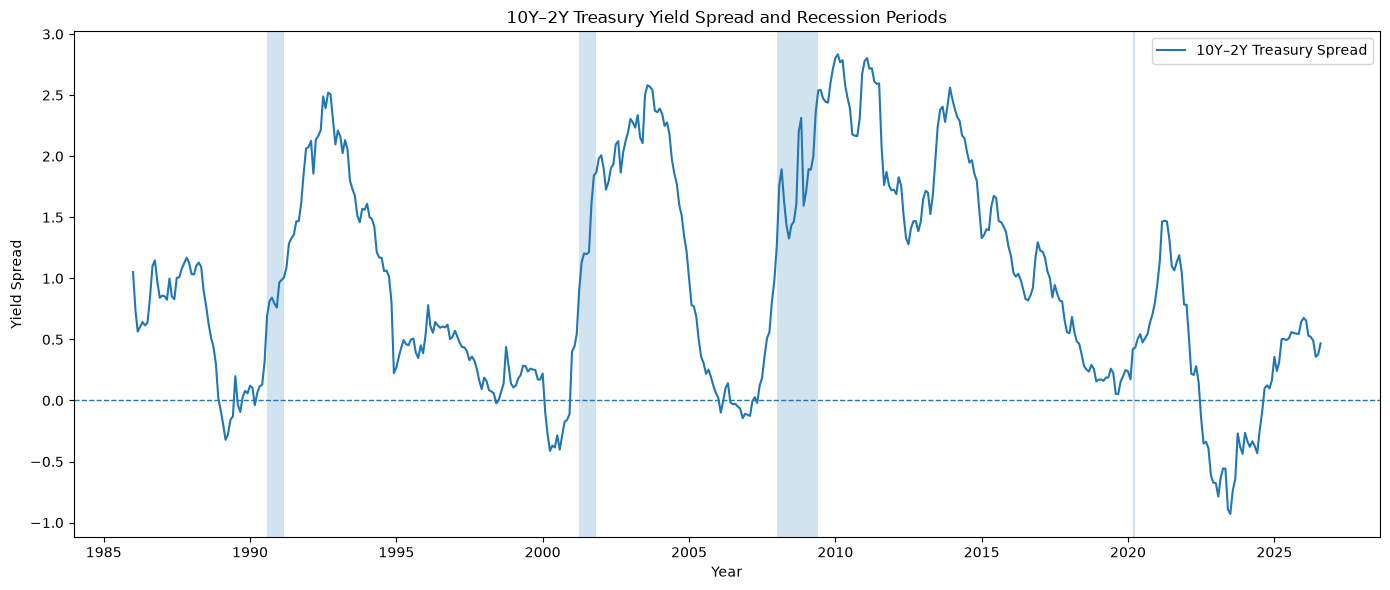

In [13]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df.index,
    df["yield_spread_10y_2y"],
    label="10Y–2Y Treasury Spread"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

for _, period in recession_periods.iterrows():
    ax.axvspan(
        period["Start"],
        period["End"],
        alpha=0.2
    )

ax.set_title("10Y–2Y Treasury Yield Spread and Recession Periods")
ax.set_xlabel("Year")
ax.set_ylabel("Yield Spread")
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "yield_curve_recessions.png", dpi=300, bbox_inches="tight")
plt.show()

The 10-year minus 2-year Treasury spread becomes negative during several
periods preceding recessions. This suggests that the yield spread may contain
useful information for recession forecasting.

However, the visual relationship alone is not sufficient to establish
predictive ability. Lagged features and out-of-sample model evaluation will
later be used to test whether this information improves recession forecasts.

## 6. Other Macroeconomic Indicators

To better understand the information available to the prediction models,
I examine several additional indicators representing economic activity,
housing, consumers and credit conditions.

In [14]:
def plot_indicator(column, title, ylabel):
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(df.index, df[column])

    for _, period in recession_periods.iterrows():
        ax.axvspan(
            period["Start"],
            period["End"],
            alpha=0.2
        )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)

    plt.tight_layout()
    plt.show()

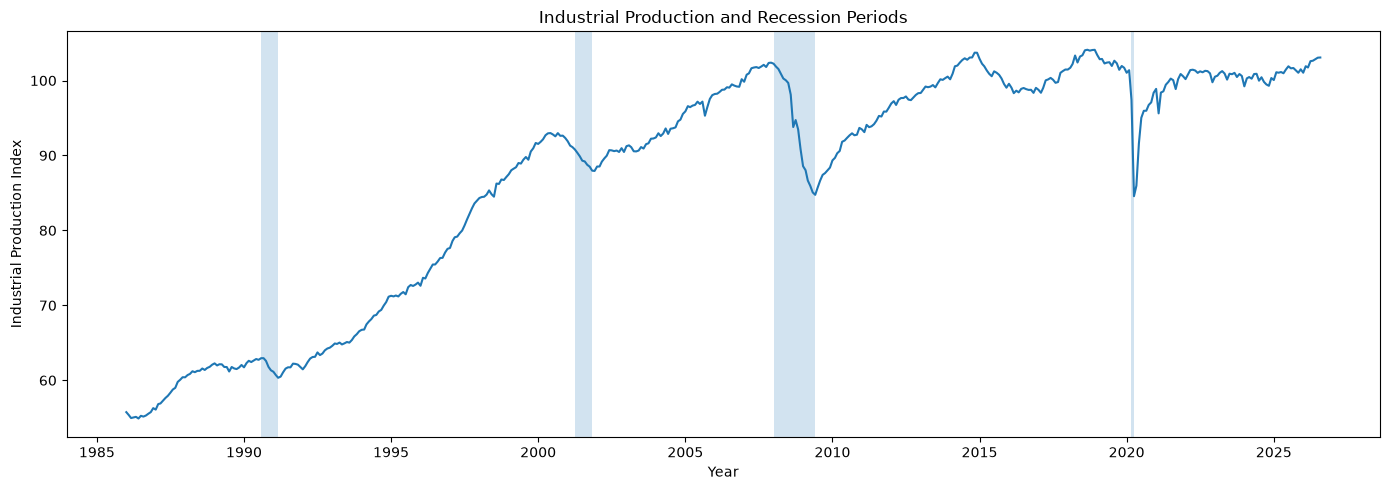

In [15]:
plot_indicator(
    "industrial_production",
    "Industrial Production and Recession Periods",
    "Industrial Production Index"
)

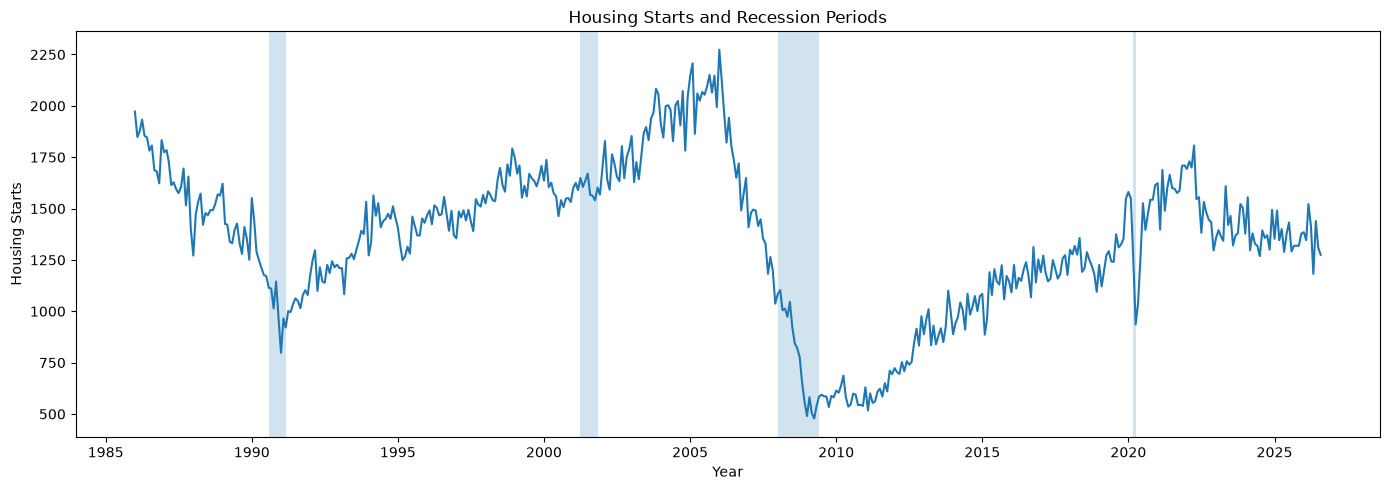

In [16]:
plot_indicator(
    "housing_starts",
    "Housing Starts and Recession Periods",
    "Housing Starts"
)

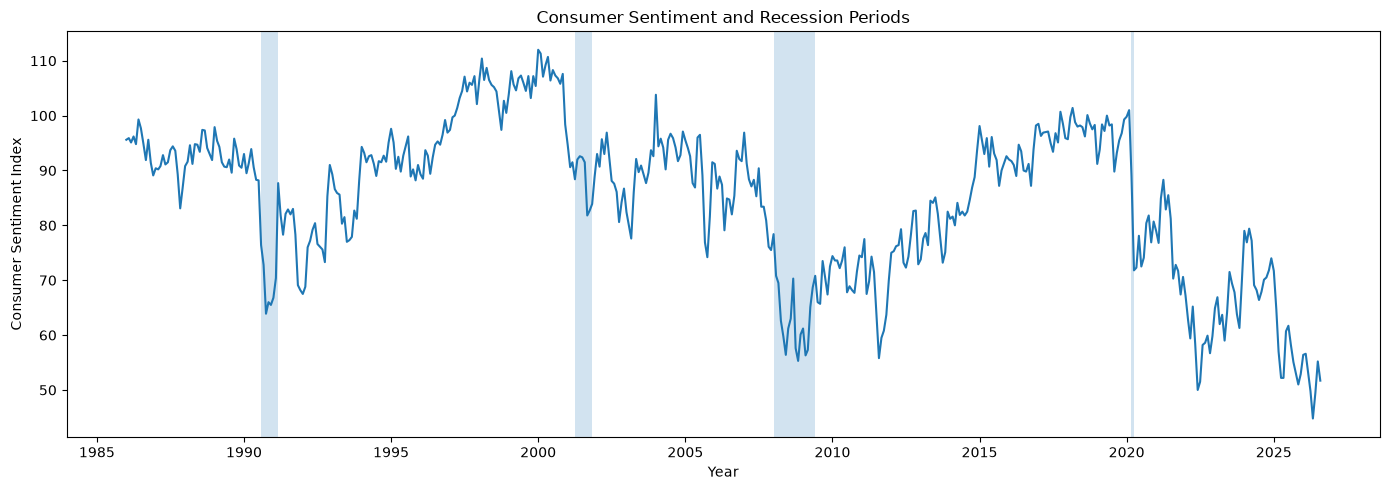

In [17]:
plot_indicator(
    "consumer_sentiment",
    "Consumer Sentiment and Recession Periods",
    "Consumer Sentiment Index"
)

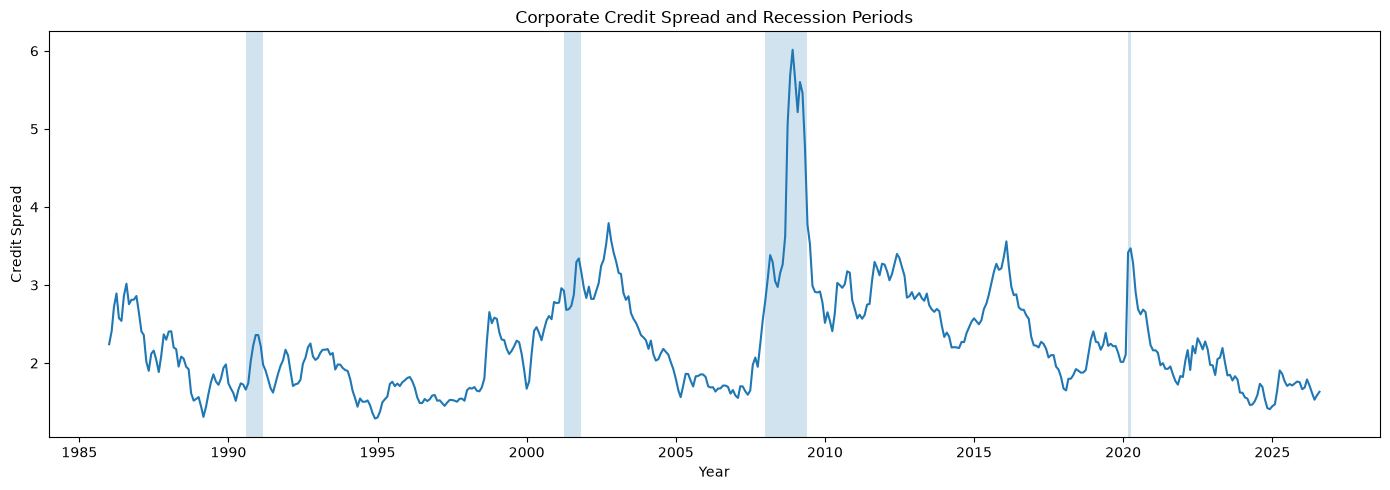

In [18]:
plot_indicator(
    "credit_spread",
    "Corporate Credit Spread and Recession Periods",
    "Credit Spread"
)

## 7. Correlation Analysis

I examine correlations between the macroeconomic indicators to identify
variables that move together and potential relationships with the recession
indicator.

These correlations describe statistical associations and should not be
interpreted as causal relationships.

In [19]:
correlation_matrix = df.corr()

correlation_matrix.round(2)

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
unemployment_rate,1.00,0.54,-0.23,-0.35,0.69,0.62,-0.29,-0.54,-0.28,0.46,0.12
initial_claims,0.54,1.00,-0.04,-0.17,0.14,0.11,-0.09,-0.14,-0.11,0.29,0.29
cpi,-0.23,-0.04,1.00,-0.54,-0.14,-0.36,0.85,-0.21,-0.53,0.06,-0.06
fed_funds_rate,-0.35,-0.17,-0.54,1.00,-0.61,-0.44,-0.63,0.38,0.29,-0.52,-0.03
yield_spread_10y_2y,0.69,0.14,-0.14,-0.61,1.00,0.91,-0.06,-0.42,-0.21,0.51,0.15
yield_spread_10y_3m,0.62,0.11,-0.36,-0.44,0.91,1.00,-0.28,-0.27,-0.05,0.39,0.12
industrial_production,-0.29,-0.09,0.85,-0.63,-0.06,-0.28,1.00,-0.10,-0.22,0.18,-0.03
housing_starts,-0.54,-0.14,-0.21,0.38,-0.42,-0.27,-0.10,1.00,0.43,-0.43,-0.25
consumer_sentiment,-0.28,-0.11,-0.53,0.29,-0.21,-0.05,-0.22,0.43,1.00,-0.25,-0.27
credit_spread,0.46,0.29,0.06,-0.52,0.51,0.39,0.18,-0.43,-0.25,1.00,0.47


In [20]:
correlation_matrix = df.corr()

recession_correlations = (
    correlation_matrix["recession"]
    .drop("recession")
    .sort_values()
)

recession_correlations

consumer_sentiment      -0.265732
housing_starts          -0.247332
cpi                     -0.058607
industrial_production   -0.030915
fed_funds_rate          -0.026262
unemployment_rate        0.118743
yield_spread_10y_3m      0.121389
yield_spread_10y_2y      0.145488
initial_claims           0.287836
credit_spread            0.471165
Name: recession, dtype: float64

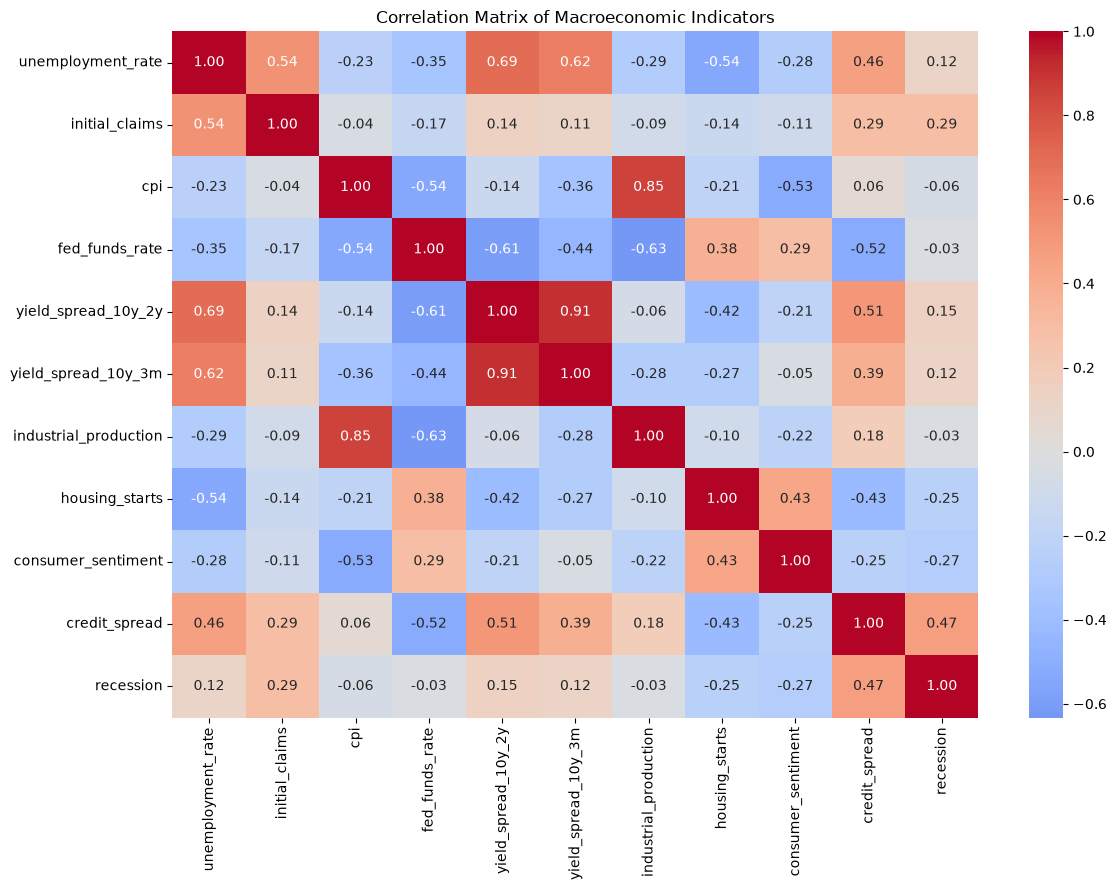

In [21]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Macroeconomic Indicators")

plt.tight_layout()
plt.show()

The correlation matrix shows that credit spreads have the strongest
positive same-month correlation with recessions, while consumer sentiment
and housing starts show negative correlations. Initial unemployment claims
also have a positive relationship with recession periods.

Some predictors are strongly correlated with each other. In particular,
the two yield spread measures have a correlation of approximately 0.91,
indicating that they contain similar information.

These correlations only describe relationships between indicators and
recessions occurring in the same month. Since the goal of this project is
to forecast recessions in advance, these results do not necessarily indicate
which variables will be the most useful predictors. Lagged and transformed
features will therefore be examined in the next stage.